# Lepton reco vs $L_{xy}$ and $\Delta R$

I want to measure the fraction of dark photon decays that result in 0, 1, or 2 (or more) electrons, photons, PF muons, and DSA muons as a function dark photon $L_xy$ and di-lepton $\Delta R$.

In [1]:
# python
import os
import sys
import numpy as np
import importlib
# columnar analysis
from coffea import processor
import hist
from hist import Hist
import awkward as ak
from dask.distributed import Client, performance_report
# local
sidm_path = str(os.getcwd()).split("/sidm")[0]
if sidm_path not in sys.path: sys.path.insert(1, sidm_path)
from sidm.tools import utilities, sidm_processor, scaleout, llpnanoaodschema
# always reload local modules to pick up changes during development
importlib.reload(utilities)
importlib.reload(sidm_processor)
importlib.reload(scaleout)
importlib.reload(llpnanoaodschema)
# plotting
import matplotlib.pyplot as plt
utilities.set_plot_style()
%matplotlib inline

Start with low-ctau sample and just plot the number of PF muons that pass the LJ source cuts and are within dR=0.5 of a dark photon that decays to muons at gen level. Choose a few different bound state and dark photon mass combos that more or less span the possible $\Delta R$ values.

In [2]:
client = scaleout.make_dask_client("tls://localhost:8786")
client

<Client: 'tls://192.168.202.30:8786' processes=1 threads=1, memory=3.82 GiB>

## Useful Functions

Would probably be good to plot these as a function of dark photon Lxy for a couple mass points. Maybe I can make 4 separate 2D hists then do some mpl magic to align them such that they share a single Lxy axis. At the moment, the normalization of these plots make them a little harder to interpret (it would be better if they were efficiency plots),

In [3]:
channels = ["base_sr"]
def make_eff(h):
    weights = 1/np.sum(h.values(), axis=-1)
    weights = np.nan_to_num(weights)
    for ix in range(h.shape[1]):
        h[:, ix] = np.column_stack([h.values()[:, ix]*weights, h.variances()[:, ix]*weights])
    return h

def plot_single(h, eff, vmax, skip_label=True, remove_xlabel=True):
    h = h[channels[0], :, :]
    if eff:
        h = make_eff(h)
    utilities.plot(h[:400j, 1:3], skip_label=skip_label, cbar=False, cmax=vmax, flow="none")
    if remove_xlabel:
        plt.xlabel(None)
    plt.draw()

def plot_all_vs_lxy(proc_output, sample, vmax=1000, eff=True, suffix=""):
    vmax = 1 if eff else vmax
    fig, ax = plt.subplots(4, 1, figsize=(30, 10), sharex=True)
    plt.subplot(4, 1, 1)
    plot_single(proc_output[sample]["hists"]["electron_nearGenA_n_genA_lxy"], eff, vmax, skip_label=False)
    plt.subplot(4, 1, 2)
    plot_single(proc_output[sample]["hists"]["photon_nearGenA_n_genA_lxy"], eff, vmax)
    plt.subplot(4, 1, 3)
    plot_single(proc_output[sample]["hists"]["muon_nearGenA_n_genA_lxy"], eff, vmax)
    plt.subplot(4, 1, 4)
    plot_single(proc_output[sample]["hists"]["dsaMuon_nearGenA_n_genA_lxy"], eff, vmax, remove_xlabel=False)
    
    fig.subplots_adjust(hspace=0)
    bs_mass, dp_mass = sample.split("_")[1:3]
    dp_mass.replace("p", ".")
    fig.suptitle(f"DM bound state mass = {bs_mass}, dark photon mass = {dp_mass}")
    cb = fig.colorbar(plt.gca().collections[0], ax=ax.ravel().tolist(), pad=0.01)
    cb.set_label("Fraction of dark photon decays", labelpad=20)
    
    #plt.savefig(f"{sidm_path}/plots/lepton_reco_vs_lxy_{sample}{suffix}.png", bbox_inches="tight")

def divide_hists(h_num, h_den, fill_value=np.nan):
    # Make sure the binning really matches
    for a_num, a_den in zip(h_num.axes, h_den.axes):
        if not np.allclose(a_num.edges, a_den.edges):
            raise ValueError(f"Bin edges differ on axis '{a_num.name}'")

    num = h_num.values()
    den = h_den.values()

    ratio = np.full_like(num, fill_value, dtype=float)
    np.divide(num, den, out=ratio, where=(den != 0))   # skip divide-by-zero bins

    h_ratio = Hist(*h_num.axes, storage=hist.storage.Double())
    h_ratio[...] = ratio
    return h_ratio

def plot_compare_2_select_vs_lxy(proc_output1, proc_output2, sample, vmax=1000, eff=True, suffix=""):
    vmax = 1 if eff else vmax
    fig, ax = plt.subplots(4, 1, figsize=(30, 10), sharex=True)
    
    plt.subplot(4, 1, 1)
    hist1 = proc_output1[sample]["hists"]["electron_nearGenA_n_genA_lxy"]
    hist2 = proc_output2[sample]["hists"]["electron_nearGenA_n_genA_lxy"]
    hist_ratio = divide_hists(hist1, hist2, fill_value=np.nan)
    plot_single(hist_ratio, eff, vmax, skip_label=False)
    
    plt.subplot(4, 1, 2)
    hist1 = proc_output1[sample]["hists"]["photon_nearGenA_n_genA_lxy"]
    hist2 = proc_output2[sample]["hists"]["photon_nearGenA_n_genA_lxy"]
    hist_ratio = divide_hists(hist1, hist2, fill_value=np.nan)
    plot_single(hist_ratio, eff, vmax)
    
    plt.subplot(4, 1, 3)
    hist1 = proc_output1[sample]["hists"]["muon_nearGenA_n_genA_lxy"]
    hist2 = proc_output2[sample]["hists"]["muon_nearGenA_n_genA_lxy"]
    hist_ratio = divide_hists(hist1, hist2, fill_value=np.nan)
    plot_single(hist_ratio, eff, vmax)
    
    plt.subplot(4, 1, 4)
    hist1 = proc_output1[sample]["hists"]["dsaMuon_nearGenA_n_genA_lxy"]
    hist2 = proc_output2[sample]["hists"]["dsaMuon_nearGenA_n_genA_lxy"]
    hist_ratio = divide_hists(hist1, hist2, fill_value=np.nan)
    plot_single(hist_ratio, eff, vmax, remove_xlabel=False)
    
    fig.subplots_adjust(hspace=0)
    bs_mass, dp_mass = sample.split("_")[1:3]
    dp_mass.replace("p", ".")
    fig.suptitle(f"DM bound state mass = {bs_mass}, dark photon mass = {dp_mass}")
    cb = fig.colorbar(plt.gca().collections[0], ax=ax.ravel().tolist(), pad=0.01)
    cb.set_label("Fraction of dark photon decays", labelpad=20)
    
    #plt.savefig(f"{sidm_path}/plots/lepton_reco_vs_lxy_{sample}{suffix}.png", bbox_inches="tight")

## Load the Outputs

In [4]:
# save all outputs
import coffea.util
# output_0p3cm = coffea.util.load('output_leptonReco_0p3cm.coffea')['out']
output_3cm = coffea.util.load('output_leptonReco_3cm.coffea')['out']
print(output_3cm.keys())
# output_30cm = coffea.util.load('output_leptonReco_30cm.coffea')['out']
output_300cm = coffea.util.load('output_leptonReco_300cm.coffea')['out']
output_3cm_noLjSourceCuts = coffea.util.load('output_leptonReco_3cm_noLjSourceCuts.coffea')['out']
print(output_3cm_noLjSourceCuts.keys())
output_300cm_noLjSourceCuts = coffea.util.load('output_leptonReco_300cm_noLjSourceCuts.coffea')['out']

dict_keys(['2Mu2E_100GeV_0p25GeV_0p2mm', '2Mu2E_100GeV_5p0GeV_4p0mm', '2Mu2E_1000GeV_0p25GeV_0p02mm', '2Mu2E_1000GeV_5p0GeV_0p4mm'])
dict_keys(['2Mu2E_100GeV_0p25GeV_0p2mm', '2Mu2E_100GeV_5p0GeV_4p0mm', '2Mu2E_1000GeV_0p25GeV_0p02mm', '2Mu2E_1000GeV_5p0GeV_0p4mm'])


## Plot

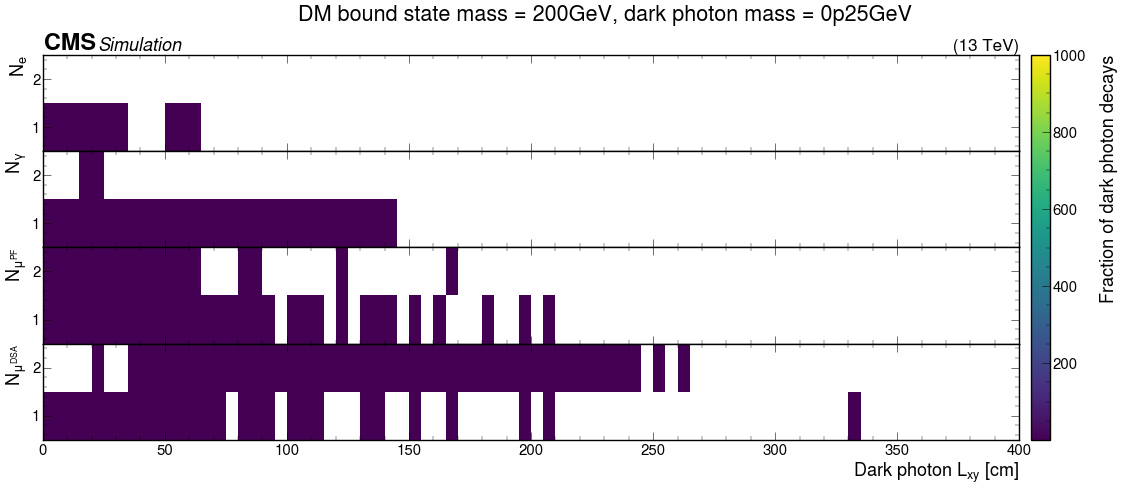

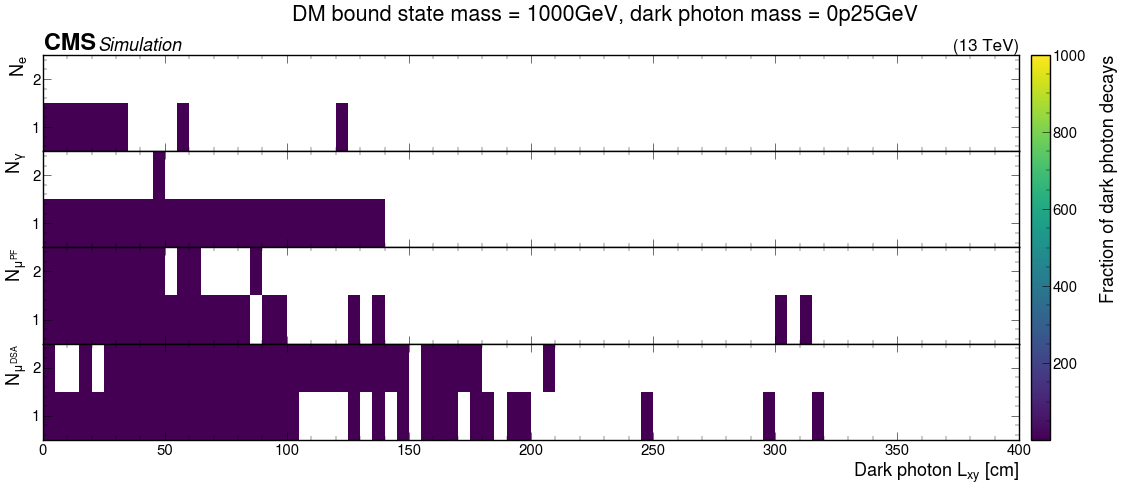

In [5]:
# plot_compare_2_select_vs_lxy(output_0p3cm, output_0p3cm, "2Mu2E_100GeV_5p0GeV_400mm")
# plot_compare_2_select_vs_lxy(output_3cm, output_3cm, "2Mu2E_100GeV_0p25GeV_20p0mm")
# plot_compare_2_select_vs_lxy(output_30cm, output_30cm, "2Mu2E_200GeV_5p0GeV_200p0mm")
plot_compare_2_select_vs_lxy(output_300cm, output_300cm_noLjSourceCuts, "2Mu2E_200GeV_0p25GeV_10p0mm", eff=False)
# plot_compare_2_select_vs_lxy(output_3cm_noLjSourceCuts, output_3cm_noLjSourceCuts, "2Mu2E_1000GeV_5p0GeV_40p0mm", eff=False)
plot_compare_2_select_vs_lxy(output_300cm_noLjSourceCuts, output_300cm_noLjSourceCuts, "2Mu2E_1000GeV_0p25GeV_2p0mm", eff=False)

## Using more exact math

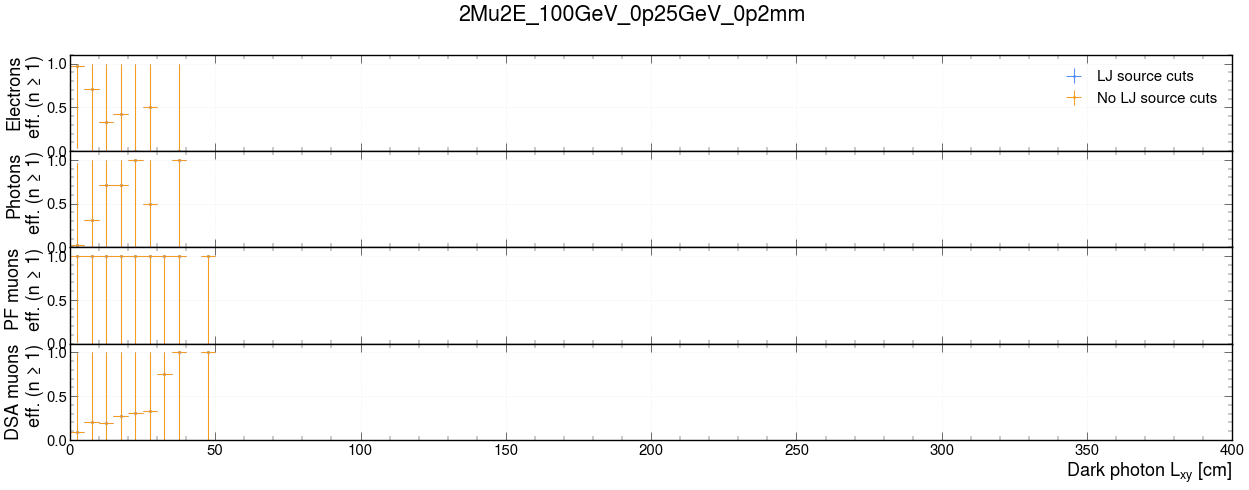

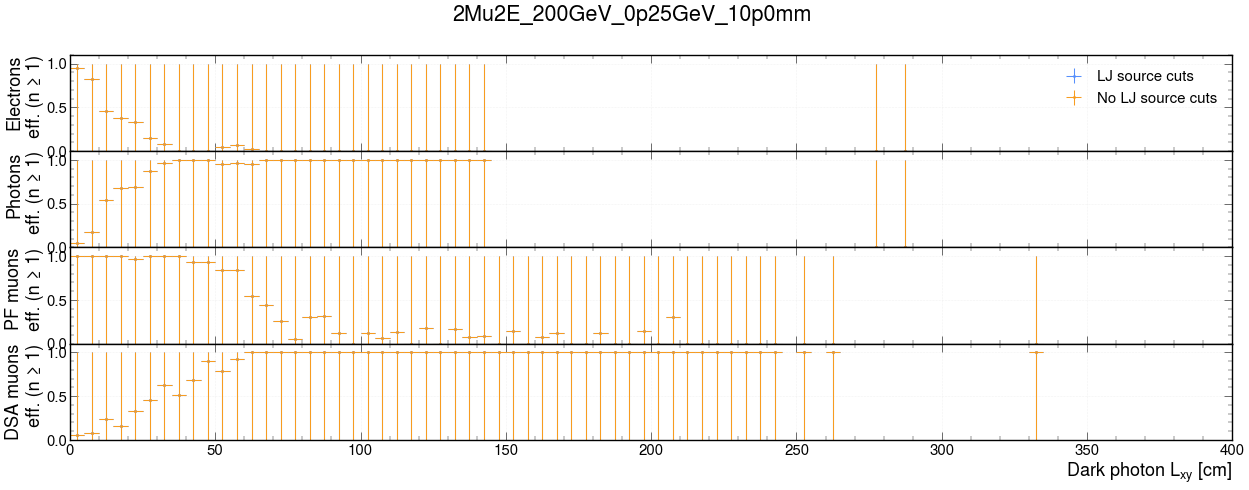

In [9]:
from lepton_eff import plot_efficiency_vs_lxy

sample = "2Mu2E_100GeV_0p25GeV_0p2mm"   # must exist in both outputs
plot_efficiency_vs_lxy(
    {"LJ source cuts": output_3cm,
     "No LJ source cuts": output_3cm_noLjSourceCuts},
    sample, min_n=1, lxy_max=400)

sample = "2Mu2E_200GeV_0p25GeV_10p0mm"   # must exist in both outputs
plot_efficiency_vs_lxy(
    {"LJ source cuts": output_300cm,
     "No LJ source cuts": output_300cm_noLjSourceCuts},
    sample, min_n=1, lxy_max=400);
